# H1: Conventional momentum can account for Grokfast's acceleration

A properly tuned conventional optimizer, without Grokfast, can achieve similar acceleration in generalization. The improvement may come from ordinary optimization effects, such as momentum or step size, rather than a special role of slowly varying gradients.



## Google Colab Setup

In [1]:
import sys
import subprocess
from pathlib import Path

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    REPO_ROOT = Path("/content/csci567-grokfast")

    if not REPO_ROOT.exists():
        subprocess.run(
            [
                "git", "clone",
                "--branch", "main",
                "https://github.com/vip11017/csci567-grokfast.git",
                str(REPO_ROOT),
            ],
            check=True,
        )
else:
    # Find the repository whether Jupyter starts in notebooks/ or the root.
    REPO_ROOT = next(
        (
            folder
            for folder in [Path.cwd(), *Path.cwd().parents]
            if (folder / "main.py").is_file()
            and (folder / "grokfast.py").is_file()
        ),
        None,
    )

    if REPO_ROOT is None:
        raise FileNotFoundError("Open this notebook inside csci567-grokfast.")

RESULTS_DIR = REPO_ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

print("Environment:", "Colab" if IN_COLAB else "Local")
print("Repository:", REPO_ROOT)
print("Results:", RESULTS_DIR)

Environment: Colab
Repository: /content/csci567-grokfast
Results: /content/csci567-grokfast/results


In [2]:
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Python:", sys.executable)
print("PyTorch:", torch.__version__)
print("Device:", device)
print("Working directory:", Path.cwd())

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print(device)

Python: /usr/bin/python3
PyTorch: 2.14.1+cu130
Device: cuda
Working directory: /content
GPU: Tesla T4


## Set up the Experiment Hyperparameters



In [3]:
# Settings held constant across the initial H1 comparisons.
SHARED_CONFIG = {
    "p": 97,
    "optimizer": "Adam",
    "lr": 0.001,
    "beta2": 0.98,
    "batch_size": 512,
    "weight_decay": 0.0,
    "budget": 50000,
}

SEEDS = [0, 1, 2]

# Analysis settings—not automatic stopping conditions in main.py.
ACCURACY_THRESHOLD = 0.95
HOLD_STEPS = 1000

print("Shared configuration:", SHARED_CONFIG)
print("Seeds:", SEEDS)

Shared configuration: {'p': 97, 'optimizer': 'Adam', 'lr': 0.001, 'beta2': 0.98, 'batch_size': 512, 'weight_decay': 0.0, 'budget': 50000}
Seeds: [0, 1, 2]


## Reproduction Check

Your first step reaching 95%: 910
Paper's reported step:        910
Last recorded step:           5000
Final validation accuracy:   99.91%


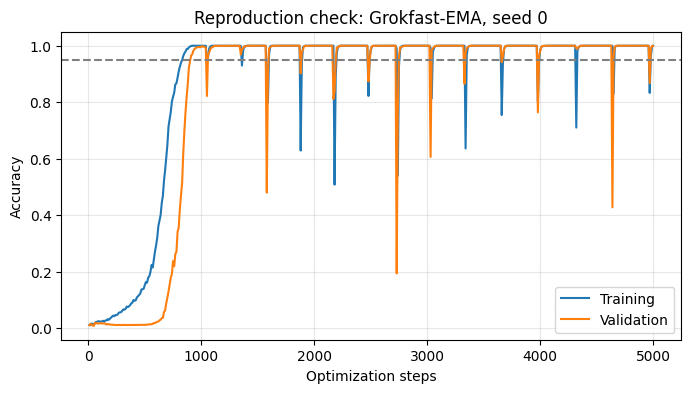

In [4]:
repro_path = (
    RESULTS_DIR
    / "res_vishal_rep_ema_s0_ema_a0980_l2_wd50e-03.pt"
)

if not repro_path.exists():
    raise FileNotFoundError(
        f"Place your previously saved reproduction file here:\n{repro_path}"
    )

repro = torch.load(
    repro_path,
    map_location="cpu",
    weights_only=True,
)

first_95 = next(
    (
        step
        for step, accuracy in zip(repro["its"], repro["val_acc"])
        if accuracy >= ACCURACY_THRESHOLD
    ),
    None,
)

print("Your first step reaching 95%:", first_95)
print("Paper's reported step:       ", 910)
print("Last recorded step:          ", repro["its"][-1])
print("Final validation accuracy:  ", f'{repro["val_acc"][-1]:.2%}')

plt.figure(figsize=(8, 4))
plt.plot(repro["its"], repro["train_acc"], label="Training")
plt.plot(repro["its"], repro["val_acc"], label="Validation")
plt.axhline(ACCURACY_THRESHOLD, color="gray", linestyle="--")
plt.xlabel("Optimization steps")
plt.ylabel("Accuracy")
plt.title("Reproduction check: Grokfast-EMA, seed 0")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## H1 Experminent Configurations

In [5]:
BUDGET = 1000

H1_CONFIGS = {
    "adam_beta090": {
        "filter": "none",
        "beta1": 0.90,
    },
    "adam_beta095": {
        "filter": "none",
        "beta1": 0.95,
    },
    "adam_beta098": {
        "filter": "none",
        "beta1": 0.98,
    },
    "adam_beta099": {
        "filter": "none",
        "beta1": 0.99,
    },
    "grokfast_ema": {
        "filter": "ema",
        "beta1": 0.90,
        "alpha": 0.98,
        "lamb": 2.0,
    },
}

for name, changes in H1_CONFIGS.items():
    settings = {**SHARED_CONFIG, **changes}
    print(name, settings)

adam_beta090 {'p': 97, 'optimizer': 'Adam', 'lr': 0.001, 'beta2': 0.98, 'batch_size': 512, 'weight_decay': 0.0, 'budget': 50000, 'filter': 'none', 'beta1': 0.9}
adam_beta095 {'p': 97, 'optimizer': 'Adam', 'lr': 0.001, 'beta2': 0.98, 'batch_size': 512, 'weight_decay': 0.0, 'budget': 50000, 'filter': 'none', 'beta1': 0.95}
adam_beta098 {'p': 97, 'optimizer': 'Adam', 'lr': 0.001, 'beta2': 0.98, 'batch_size': 512, 'weight_decay': 0.0, 'budget': 50000, 'filter': 'none', 'beta1': 0.98}
adam_beta099 {'p': 97, 'optimizer': 'Adam', 'lr': 0.001, 'beta2': 0.98, 'batch_size': 512, 'weight_decay': 0.0, 'budget': 50000, 'filter': 'none', 'beta1': 0.99}
grokfast_ema {'p': 97, 'optimizer': 'Adam', 'lr': 0.001, 'beta2': 0.98, 'batch_size': 512, 'weight_decay': 0.0, 'budget': 50000, 'filter': 'ema', 'beta1': 0.9, 'alpha': 0.98, 'lamb': 2.0}


## H1 Experiments:
- Experiment 1: Standard Adam, \Beta_{1} = 0.90, Grokfast Off
- Experiment 2: Higher-momentum Adam, \Beta_{1} = 0.95, Grokfast Off
- Experiment 3: Higher-momentum Adam, \Beta_{1} = 0.98, Grokfast Off
- Experiment 4: Higher-momentum Adam, \Beta_{1} = 0.99, Grokfast off
- Experiment 5: Adam + Grokfast-EMA, Standard Adam Momentum + Grokfast

In [6]:
%cd "{REPO_ROOT}"
for seed in SEEDS:
  print(f"Running experiment 1 with seed: {seed}")
  !"{sys.executable}" -u main.py \
      --label h1_adam090_s{seed}_b{BUDGET} \
      --seed {seed} \
      --budget {BUDGET} \
      --optimizer Adam \
      --lr 0.001 \
      --batch_size 512 \
      --beta1 0.90 \
      --beta2 0.98 \
      --weight_decay 0 \
      --filter none

/content/csci567-grokfast
Running experiment 1 with seed: 0
Experiment results saved under name: h1_adam090_s0_b1000_none
Using Device: cuda
Decoder(
  (token_embeddings): Embedding(99, 128)
  (position_embeddings): Embedding(5, 128)
  (layers): ModuleList(
    (0-1): 2 x Block(
      (ln_1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln_2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
      )
      (mlp): Sequential(
        (0): Linear(in_features=128, out_features=512, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=512, out_features=128, bias=True)
      )
    )
  )
  (ln_f): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=128, out_features=99, bias=False)
)
Total number of parameters: 422784
100% 100/100 [00:11<00:00,  9.02it

In [7]:
for seed in SEEDS:
  print(f"Running experiment 2 with seed: {seed}")
  !"{sys.executable}" -u main.py \
      --label h1_adam095_s{seed}_b{BUDGET} \
      --seed {seed} \
      --budget {BUDGET} \
      --optimizer Adam \
      --lr 0.001 \
      --batch_size 512 \
      --beta1 0.95 \
      --beta2 0.98 \
      --weight_decay 0 \
      --filter none

Running experiment 2 with seed: 0
Experiment results saved under name: h1_adam095_s0_b1000_none
Using Device: cuda
Decoder(
  (token_embeddings): Embedding(99, 128)
  (position_embeddings): Embedding(5, 128)
  (layers): ModuleList(
    (0-1): 2 x Block(
      (ln_1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln_2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
      )
      (mlp): Sequential(
        (0): Linear(in_features=128, out_features=512, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=512, out_features=128, bias=True)
      )
    )
  )
  (ln_f): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=128, out_features=99, bias=False)
)
Total number of parameters: 422784
100% 100/100 [00:11<00:00,  8.70it/s]
Running experiment 2 w

In [8]:
for seed in SEEDS:
  print(f"Running experiment 3 with seed: {seed}")
  !"{sys.executable}" -u main.py \
      --label h1_adam098_s{seed}_b{BUDGET} \
      --seed {seed} \
      --budget {BUDGET} \
      --optimizer Adam \
      --lr 0.001 \
      --batch_size 512 \
      --beta1 0.98 \
      --beta2 0.98 \
      --weight_decay 0 \
      --filter none

Running experiment 3 with seed: 0
Experiment results saved under name: h1_adam098_s0_b1000_none
Using Device: cuda
Decoder(
  (token_embeddings): Embedding(99, 128)
  (position_embeddings): Embedding(5, 128)
  (layers): ModuleList(
    (0-1): 2 x Block(
      (ln_1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln_2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
      )
      (mlp): Sequential(
        (0): Linear(in_features=128, out_features=512, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=512, out_features=128, bias=True)
      )
    )
  )
  (ln_f): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=128, out_features=99, bias=False)
)
Total number of parameters: 422784
100% 100/100 [00:11<00:00,  8.79it/s]
Running experiment 3 w

In [9]:
for seed in SEEDS:
  print(f"Running experiment 4 with seed: {seed}")
  !"{sys.executable}" -u main.py \
      --label h1_adam099_s{seed}_b{BUDGET} \
      --seed {seed} \
      --budget {BUDGET} \
      --optimizer Adam \
      --lr 0.001 \
      --batch_size 512 \
      --beta1 0.99 \
      --beta2 0.98 \
      --weight_decay 0 \
      --filter none

Running experiment 4 with seed: 0
Experiment results saved under name: h1_adam099_s0_b1000_none
Using Device: cuda
Decoder(
  (token_embeddings): Embedding(99, 128)
  (position_embeddings): Embedding(5, 128)
  (layers): ModuleList(
    (0-1): 2 x Block(
      (ln_1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln_2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
      )
      (mlp): Sequential(
        (0): Linear(in_features=128, out_features=512, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=512, out_features=128, bias=True)
      )
    )
  )
  (ln_f): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=128, out_features=99, bias=False)
)
Total number of parameters: 422784
100% 100/100 [00:11<00:00,  8.76it/s]
Running experiment 4 w

In [10]:
for seed in SEEDS:
  print(f"Running experiment 5 with seed: {seed}")
  !"{sys.executable}" -u main.py \
      --label h1_grokfast_ema_s{seed}_b{BUDGET} \
      --seed {seed} \
      --budget {BUDGET} \
      --optimizer Adam \
      --lr 0.001 \
      --batch_size 512 \
      --beta1 0.90 \
      --beta2 0.98 \
      --weight_decay 0 \
      --filter ema \
      --alpha 0.98 \
      --lamb 2.0

Running experiment 5 with seed: 0
Experiment results saved under name: h1_grokfast_ema_s0_b1000_ema_a0980_l2
Using Device: cuda
Decoder(
  (token_embeddings): Embedding(99, 128)
  (position_embeddings): Embedding(5, 128)
  (layers): ModuleList(
    (0-1): 2 x Block(
      (ln_1): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln_2): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
      )
      (mlp): Sequential(
        (0): Linear(in_features=128, out_features=512, bias=True)
        (1): GELU(approximate='none')
        (2): Linear(in_features=512, out_features=128, bias=True)
      )
    )
  )
  (ln_f): LayerNorm((128,), eps=1e-05, elementwise_affine=True, bias=True)
  (head): Linear(in_features=128, out_features=99, bias=False)
)
Total number of parameters: 422784
100% 100/100 [00:12<00:00,  8.19it/s]
Running e

## Experiment Results

In [11]:
RESULTS_DIR = REPO_ROOT / "results"

print("Current budget:", BUDGET)
print("Current seeds:", SEEDS)

result_files = sorted(
    RESULTS_DIR.glob(f"res_h1_*_s*_b{BUDGET}_*.pt")
)

print("Matching result files:", len(result_files))

for path in result_files:
    result = torch.load(
        path,
        map_location="cpu",
        weights_only=True,
    )

    first_95 = next(
        (
            step
            for step, accuracy
            in zip(result["its"], result["val_acc"])
            if accuracy >= 0.95
        ),
        None,
    )

    last_step = result["its"][-1]
    status = "Complete" if last_step >= BUDGET else "Partial"

    print(
        f"\n{path.name}\n"
        f"  Status: {status}\n"
        f"  Last recorded step: {last_step}\n"
        f"  First 95%: {first_95}\n"
        f"  Final validation accuracy: {result['val_acc'][-1]:.2%}"
    )

Current budget: 1000
Current seeds: [0, 1, 2]
Matching result files: 15

res_h1_adam090_s0_b1000_none.pt
  Status: Complete
  Last recorded step: 1000
  First 95%: None
  Final validation accuracy: 9.88%

res_h1_adam090_s1_b1000_none.pt
  Status: Complete
  Last recorded step: 1000
  First 95%: None
  Final validation accuracy: 28.97%

res_h1_adam090_s2_b1000_none.pt
  Status: Complete
  Last recorded step: 1000
  First 95%: None
  Final validation accuracy: 23.54%

res_h1_adam095_s0_b1000_none.pt
  Status: Complete
  Last recorded step: 1000
  First 95%: None
  Final validation accuracy: 3.33%

res_h1_adam095_s1_b1000_none.pt
  Status: Complete
  Last recorded step: 1000
  First 95%: None
  Final validation accuracy: 15.23%

res_h1_adam095_s2_b1000_none.pt
  Status: Complete
  Last recorded step: 1000
  First 95%: None
  Final validation accuracy: 9.47%

res_h1_adam098_s0_b1000_none.pt
  Status: Complete
  Last recorded step: 1000
  First 95%: None
  Final validation accuracy: 1.48%



## Analyze and Visualize Results

In [12]:
import re
import pandas as pd

rows = []

for path in sorted(RESULTS_DIR.glob(f"res_h1_*_b{BUDGET}_*.pt")):
    match = re.match(r"res_h1_(.+)_s(\d+)_b(\d+)_", path.stem)
    if match is None:
        continue

    condition, seed, budget = match.groups()

    result = torch.load(
        path,
        map_location="cpu",
        weights_only=True,
    )

    first_95 = next(
        (
            step
            for step, accuracy
            in zip(result["its"], result["val_acc"])
            if accuracy >= ACCURACY_THRESHOLD
        ),
        None,
    )

    rows.append({
        "condition": condition,
        "seed": int(seed),
        "budget": int(budget),
        "last_step": result["its"][-1],
        "complete": result["its"][-1] >= int(budget),
        "first_95": first_95,
        "final_val_accuracy": result["val_acc"][-1],
    })

run_results = pd.DataFrame(rows)

if run_results.empty:
    raise FileNotFoundError("No matching H1 result files were found.")

run_results = run_results.sort_values(["condition", "seed"])
display(run_results)

,condition,seed,budget,last_step,complete,first_95,final_val_accuracy
0,adam090,0,1000,1000,True,None,0.098797
1,adam090,1,1000,1000,True,None,0.289734
2,adam090,2,1000,1000,True,None,0.235395
3,adam095,0,1000,1000,True,None,0.033290
4,adam095,1,1000,1000,True,None,0.152277
5,adam095,2,1000,1000,True,None,0.094716
6,adam098,0,1000,1000,True,None,0.014820
7,adam098,1,1000,1000,True,None,0.039089
8,adam098,2,1000,1000,True,None,0.045318
9,adam099,0,1000,1000,True,None,0.013531


## Interpretation

## Limitations and Provenance